# Parentheticals: what the hecklers say

**Exploratory, not a pipeline.** Task 4 counted heckles. This notebook reads
them: the words inside `Vadai Ágnes: Nem hallom!` and `Közbeszólás az MSZP
soraiból: Hazudik!`. It asks four questions:

- Which heckles are stock formulas?
- How do government and opposition benches heckle differently?
- When Fidesz moved from government (cycle 42) to opposition (cycle 43), did
  its heckling change with it?
- What affect do the pooled heckles carry?

The data rules are the same as in notebooks 01 and 02:

- **Block-deduplicated view.** The plan said `collapse_consecutive`, but
  notebook 01 showed that collapsing leaves the copied blocks in place. Those
  blocks are disproportionately heckles: the 176 copies of the 2018 protest
  block are mostly interjections.
- **Full quotes.** `Event.quote` stops at the first sentence end (notebook 02,
  §4), so the continuation sentences are re-attached here.
- **Hyphenated-name interjectors are recovered.** Task 4 misses them (notebook
  02, §4). Here they are included and flagged.

In [1]:
import dataclasses
import json
import re
import subprocess
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from keyflux import Keyness, RankedList, allotaxonograph, rtd

from parlamonitor.emtsv import Token, analyse_lines, is_content_word
from parlamonitor.interactions import SpeakerRegistry
from parlamonitor.lexicon import EKMAN, EKMAN_FILES, fold, load_lexicon, score_emotion, score_sentiment
from parlamonitor.loading import load_speeches
from parlamonitor.heckles import HECKLE_STOP_EXTRAS, bench_of, content_lemmas as heckle_lemmas, quotes_in, quotes_in_line
from parlamonitor.parentheticals import CYCLES, NORMALISATION_VERSION, block_dedup, file_sha256, load_parentheticals, parentheticals_path
from parlamonitor.reactions import GOVERNING_PARTIES
from parlamonitor.stopwords import hungarian_stopwords

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
SCRATCH = ROOT / "data" / "derived" / "explore"
SCRATCH.mkdir(parents=True, exist_ok=True)
LEXICONS = ROOT / "data" / "lexicons"
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 150)


def rel(path):
    path = Path(path).resolve()
    try:
        return str(path.relative_to(ROOT))
    except ValueError:
        return path.name

## Parameters and provenance

Every parameter below changes the numbers.

In [2]:
PARAMS = {
    "view": "block-dedup (window of 10 runs), as in notebook 01",
    # Stock-heckle identity: case-folded, punctuation stripped, whitespace collapsed.
    "stock_normalisation": "casefold + strip punctuation",
    "stock_top_n": 20,
    # Keyness: log-likelihood significance, log-ratio effect size (keyflux defaults).
    "keyness_measure": "log_likelihood",
    "keyness_min_freq": 5,
    # Minimum keyflux significance band: LL >= 10.83 (p < 0.001). Hundreds of words are
    # tested per contrast, uncorrected, so p < 0.05 would admit noise.
    "keyness_min_band": "p001",
    # Lemmas counted for keyness and RTD: content words only (N, V, Adj, Adv; no pronouns) ...
    "content_words_only": True,
    # ... minus the project stoplist (spaCy hu + light verbs + chamber address terms, the
    # Task 2 list) and the four genuine additions NLTK's Hungarian list makes to it (§4).
    "stopwords": "parlamonitor.stopwords.hungarian_stopwords() + NLTK extras",
    "stopword_extras": ["első", "elő", "először", "ők"],
    "rtd_alpha": 1 / 3,
    # Affect is pooled per bench and cycle; a single heckle averages under 5 words.
    "affect_pooling": "side x cycle",
    "sentiment_balanced": False,
    "emotion_min_hits": 5,
}


# Block copies removed with the detector notebook 01 introduced, now in src/.
corpus = {c: block_dedup(load_parentheticals(c)[0]) for c in CYCLES}

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
print(json.dumps({
    "git_commit": commit,
    "normalisation": NORMALISATION_VERSION,
    "sources": [{"cycle": c, "path": rel(parentheticals_path(c)), "sha256": file_sha256(parentheticals_path(c))[:16],
                 "lines_block_dedup": len(corpus[c])} for c in CYCLES],
    "params": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in PARAMS.items()},
}, indent=1, ensure_ascii=False))

{
 "git_commit": "a883a50",
 "normalisation": "strip-soft-hyphen-1",
 "sources": [
  {
   "cycle": 39,
   "path": "data/raw/parantheticals/cycle39-parentheticals.txt",
   "sha256": "852bbebfe9168acd",
   "lines_block_dedup": 59891
  },
  {
   "cycle": 40,
   "path": "data/raw/parantheticals/cycle40-parentheticals.txt",
   "sha256": "749b28abb9df40ac",
   "lines_block_dedup": 50816
  },
  {
   "cycle": 41,
   "path": "data/raw/parantheticals/cycle41-parentheticals.txt",
   "sha256": "e3523eb1b6a97378",
   "lines_block_dedup": 46169
  },
  {
   "cycle": 42,
   "path": "data/raw/parantheticals/cycle42-parentheticals.txt",
   "sha256": "74035ed57eb41b32",
   "lines_block_dedup": 33639
  },
  {
   "cycle": 43,
   "path": "data/raw/parantheticals/cycle43-parentheticals.txt",
   "sha256": "2a1f3b86abf6b2bc",
   "lines_block_dedup": 5794
  }
 ],
 "params": {
  "view": "block-dedup (window of 10 runs), as in notebook 01",
  "stock_normalisation": "casefold + strip punctuation",
  "stock_top_n":

## 1. The quote corpus

A quote is whatever follows `Name:` or `Közbeszólás a … soraiból:`. It runs to
the end of its ` - ` piece, or until the next segment that is itself a reaction
(`Taps.`, `Derültség.`). The reading is `parlamonitor.heckles.quotes_in`, which
was promoted from this notebook. `scripts/heckle_content.py` runs the same code
for the dashboard.

In [3]:
[demo] = quotes_in("Dr. Varga László: Mit nevetgéltek ezen? Inkább szégyelljétek magatokat! Minden érvénytelen!")
assert demo.quote == "Mit nevetgéltek ezen? Inkább szégyelljétek magatokat! Minden érvénytelen!", demo
assert quotes_in("Dr. Kátai-Németh Vilmos: Igen!")[0].speaker == "Kátai-Németh Vilmos"
assert quotes_in("Taps a kormánypárt soraiban.") == []

rows = [
    {"cycle": c, **dataclasses.asdict(q)}
    for c in CYCLES for line in corpus[c] for q in quotes_in_line(line)
]
quotes = pd.DataFrame(rows)
quotes["named"] = quotes["speaker"].notna()
quotes.groupby("cycle").agg(
    quotes=("quote", "size"), named=("named", "sum"),
    reassembled=("reassembled", "sum"), hyphenated_recovered=("hyphenated_recovered", "sum"),
)

,quotes,named,reassembled,hyphenated_recovered
cycle,,,,
39,13459,9671,1185,270
40,15288,12937,1672,14
41,14121,11920,1669,524
42,12176,11070,1348,201
43,1718,1358,176,24


### Who said it: bench attribution

There are three routes to a bench:

- **Bench in the note.** `Közbeszólás a Fidesz soraiból: …` names a party,
  and `… a kormánypártok soraiból` names a side. Parties map to a side through
  `reactions.side_of`, per cycle.
- **Named, cycle 43.** The speaker is resolved through the cycle-43 speeches
  export (`SpeakerRegistry`), which knows each member's faction.
- **Named, cycles 39–42.** No route. These files carry no party for a named
  interjector, and no speeches export exists for those cycles. **They stay
  unattributed.** Guessing a heckler's party from the benches mentioned
  around them would be inventing data.

In [4]:
speeches = load_speeches()
registry = SpeakerRegistry((r.get("speaker") or {} for r in speeches), governing=GOVERNING_PARTIES[43])


def attribute(row):
    # heckles.bench_of: the registry only exists for cycle 43.
    q = quotes_in_line_cache[row.name]
    return bench_of(q, row["cycle"], registry if row["cycle"] == 43 else None)


quotes_in_line_cache = [q for c in CYCLES for line in corpus[c] for q in quotes_in_line(line)]
attributed = quotes.apply(attribute, axis=1, result_type="expand")
quotes[["side", "party_group", "route"]] = attributed
route_table = quotes.pivot_table(index="route", columns="cycle", values="quote", aggfunc="size", fill_value=0)
route_table["all"] = route_table.sum(axis=1)
assert route_table["all"].sum() == len(quotes)
route_table

cycle,39,40,41,42,43,all
route,,,,,,
bench in the note,3372,2155,1993,997,332,8849
bench not stated,416,196,208,109,28,957
"named, no party data",9671,12937,11920,11070,0,45598
"named, resolved",0,0,0,0,1352,1352
"named, unresolved",0,0,0,0,6,6


In [5]:
(quotes.fillna({"side": "unattributed", "party_group": "unsettled"})
 .pivot_table(index=["side", "party_group"], columns="cycle", values="quote", aggfunc="size", fill_value=0))

cycle                        39     40     41     42   43
side         party_group                                 
government   Fidesz-KDNP   1589    549    934    514    0
             other           17      5      2      4  739
opposition   Fidesz-KDNP      2      1      3      4  733
             other         1746   1586   1043    470  179
             unsettled        0      0      0      0   32
unattributed unsettled    10105  13147  12139  11184   35

The attributed sample is lopsided. Most quotes are named, and named quotes
can be attributed only in cycle 43. So bench comparisons for cycles 39–42 rest
on **unnamed** heckles, the ones the note-taker attributed to a bench rather
than a person. Those are shorter and more formulaic than named interjections.
A difference between cycles 42 and 43 is partly a difference in which route
the quotes came through.

## 2. Stock heckles

A heckle is "stock" when the same words recur verbatim. Case and punctuation
are ignored: *Szégyen!* and *szégyen.* are one formula.

In [6]:
def normalise_quote(text):
    return " ".join(re.sub(r"[^\w\s]", " ", text.casefold()).split())


assert normalise_quote("Szégyen! Szégyen!") == "szégyen szégyen"
quotes["formula"] = quotes["quote"].map(normalise_quote)
quotes = quotes[quotes["formula"] != ""].reset_index(drop=True)

N = PARAMS["stock_top_n"]
rows = []
for c in CYCLES:
    counts = quotes.loc[quotes.cycle == c, "formula"].value_counts()
    rows.append({"cycle": c, "quotes": int(counts.sum()), "distinct": len(counts),
                 f"top-{N} share": f"{counts.head(N).sum() / counts.sum():.1%}",
                 "said exactly once": f"{(counts == 1).sum() / counts.sum():.1%}"})
pd.DataFrame(rows).set_index("cycle")

,quotes,distinct,top-20 share,said exactly once
cycle,,,,
39,13459,9820,14.2%,67.6%
40,15288,12124,10.5%,74.8%
41,14121,10227,14.3%,66.4%
42,12176,9116,11.6%,68.9%
43,1718,1371,14.6%,73.9%


In [7]:
top_by_cycle = {c: quotes.loc[quotes.cycle == c, "formula"].value_counts().head(10) for c in CYCLES}
pd.DataFrame({c: [f"{f} ({n})" for f, n in s.items()] for c, s in top_by_cycle.items()}).rename_axis("rank").rename(index=lambda i: i + 1)

,39,40,41,42,43
rank,,,,,
1,így van (392),így van (372),így van (564),így van (387),így van (60)
2,igen (323),úgy van (225),úgy van (223),igen (204),úgy van (36)
3,úgy van (254),igen (206),igen (210),nem (122),nem (15)
4,nem (154),szégyen (138),szégyen (193),szégyen (91),igen (13)
5,szégyen (147),nem (130),nem (144),nem igaz (77),szégyen (12)
6,elfogadom (91),nem igaz (118),nem igaz (131),úgy van (70),ez nem igaz (11)
7,bravó (83),ez nem igaz (61),szégyelld magad (70),ez nem igaz (58),bravó (11)
8,jaj (72),jaj (42),ez nem igaz (62),biztos hogy nem (55),hazudsz (10)
9,nem igaz (47),szégyelld magad (34),jaj (57),szégyelld magad (50),jaj (10)


Every cycle's list opens with **assent**: *így van*, *úgy van*, *igen*
("that's right", "yes"). After that come **denial** and **shame**: *nem*,
*nem igaz*, *ez nem igaz* ("no", "not true"); *szégyen*, *szégyelld magad*
("shame", "shame on you").

Yet the top 20 formulas cover only 10–15% of all heckles. Two-thirds to
three-quarters of heckles are said exactly once. The register is formulaic at
the top and improvised underneath, which is why reading the quotes is worth
more than counting them.

## 3. Who heckles, and at whom

In [8]:
named = quotes[quotes.named]
top_hecklers = (named.groupby(["cycle", "speaker"]).size().rename("quotes").reset_index()
                .sort_values(["cycle", "quotes"], ascending=[True, False]).groupby("cycle").head(5))
top_hecklers["hyphenated, missed by Task 4"] = top_hecklers["speaker"].str.contains("-")
top_hecklers.reset_index(drop=True)

,cycle,speaker,quotes,"hyphenated, missed by Task 4"
0,39,Józsa István,1015,False
1,39,Babák Mihály,719,False
2,39,Gőgös Zoltán,513,False
3,39,Nyakó István,348,False
4,39,Novák Előd,313,False
5,40,Gőgös Zoltán,1331,False
6,40,Bangóné Borbély Ildikó,684,False
7,40,Bárándy Gergely,641,False
8,40,Józsa István,558,False
9,40,Schiffer András,501,False


In [9]:
addressed = quotes[quotes.addressee.notna()]
print(f"{len(addressed):,} quotes name an addressee ('X Y-nak:'); Task 4's CSV drops this field.")
(addressed.groupby(["cycle", "addressee"]).size().rename("quotes").reset_index()
 .sort_values(["cycle", "quotes"], ascending=[True, False]).groupby("cycle").head(3).reset_index(drop=True))

73 quotes name an addressee ('X Y-nak:'); Task 4's CSV drops this field.


,cycle,addressee,quotes
0,39,Gőgös Zoltán,2
1,39,Tállai András,2
2,39,Cseresnyés Péter,1
3,40,Dömötör Csaba,2
4,40,Cseresnyés Péter,1
5,40,Font Sándor,1
6,41,Nacsa Lőrinc,3
7,41,Tordai Bence,3
8,41,Szabó Timea,2
9,42,Kálmán Olga,5


## 4. Lemmatising the quotes

Distinct quotes go to emtsv once, batched with the same line-aligned client as
Task 3, and are cached to `data/derived/explore/quote_lemma_cache.jsonl`. A
re-run with a warm cache needs no service.

The notebook-01 name and `Mi Hazánk` repairs are **not** applied. They are
prototypes, not yet in `src/`, and they were built for the note-taker's prose.
These quotes are members' own words, where a surname is rare.

In [10]:
CACHE = SCRATCH / "quote_lemma_cache.jsonl"
cached = {}
if CACHE.exists():
    with CACHE.open(encoding="utf-8") as handle:
        for raw in handle:
            record = json.loads(raw)
            cached[record["quote"]] = record["sentences"]

todo = sorted(set(quotes["quote"]) - set(cached))
print(f"{quotes['quote'].nunique():,} distinct quotes; {len(cached):,} cached; {len(todo):,} to analyse")
if todo:
    with requests.Session() as session:
        analysed = analyse_lines(todo, session=session)
    with CACHE.open("a", encoding="utf-8") as handle:
        for quote, sentences in zip(todo, analysed, strict=True):
            serial = [[[t.form, t.lemma, t.xpostag] for t in sentence] for sentence in sentences]
            cached[quote] = serial
            handle.write(json.dumps({"quote": quote, "sentences": serial}, ensure_ascii=False) + "\n")
missing = set(quotes["quote"]) - set(cached)
assert not missing, f"{len(missing)} quotes have no analysis"

40,881 distinct quotes; 40,881 cached; 0 to analyse


### Stopwords

Content words only (nouns, verbs, adjectives, adverbs; no pronouns) still
leaves the words every heckle uses whatever it is about: *van*, *mond*, *kér*,
*szól*, *ne*, *most*, *asszony*. The stoplist removes them. It is the project's
own Task 2 list, `parlamonitor.stopwords.hungarian_stopwords()`, built from
three groups that can each be switched off:

- spaCy's Hungarian list, which is the one HuSpaCy uses;
- light and support verbs;
- the chamber's address terms.

NLTK's Hungarian list was compared rather than assumed. It is almost a
subset of spaCy's. Its only extra entries are spelled with `õ` (o-tilde, a
Latin-1 encoding error) where `ő` belongs. Repaired, four are genuinely
missing from spaCy's list, and those four are added. The comparison needs
NLTK's `stopwords` corpus, which is downloaded data, so the cell skips itself
on a clean install.

In [11]:
assert tuple(PARAMS["stopword_extras"]) == HECKLE_STOP_EXTRAS
STOP = hungarian_stopwords(extra=PARAMS["stopword_extras"])
print(f"stoplist: {len(STOP)} lemmas")

try:
    from nltk.corpus import stopwords as nltk_stopwords
    from parlamonitor.stopwords import SPACY_HU

    nltk_hu = set(nltk_stopwords.words("hungarian"))
    nltk_only = sorted(nltk_hu - SPACY_HU)
    repaired = {w.replace("õ", "ő") for w in nltk_hu}
    print(f"NLTK: {len(nltk_hu)} words; not in spaCy as spelled: {nltk_only}")
    print(f"NLTK with õ→ő repaired, not in spaCy: {sorted(repaired - SPACY_HU)}")
    assert sorted(repaired - SPACY_HU) == sorted(PARAMS["stopword_extras"])
except LookupError:
    print("NLTK stopwords corpus not downloaded; comparison skipped (the extras above are fixed).")

stoplist: 282 lemmas


NLTK: 198 words; not in spaCy as spelled: ['elsõ', 'elõ', 'elõször', 'elõtt', 'õ', 'õk', 'õket']
NLTK with õ→ő repaired, not in spaCy: ['első', 'elő', 'először', 'ők']


In [12]:
def content_lemmas(quote):
    return heckle_lemmas(cached[quote], STOP, content_only=PARAMS["content_words_only"])


def counts_for(mask):
    total = Counter()
    for quote in quotes.loc[mask, "quote"]:
        total.update(content_lemmas(quote))
    return total


print("Example:", quotes.loc[0, "quote"], "→", content_lemmas(quotes.loc[0, "quote"]))

Example: A kormányzásról beszélj! → ['kormányzás']


## 5. Government versus opposition heckles, cycle by cycle

Log-likelihood keyness (keyflux) of the opposition benches' heckles against the
government benches' heckles, using content lemmas. `+` marks words
characteristic of the opposition and `−` words characteristic of the
government. Only words at or above the p < 0.001 band (LL ≥ 10.83) are listed,
ranked by effect size (log ratio).

In [13]:
def keyness(focus, reference, top=10):
    k = Keyness(focus, reference, measure=PARAMS["keyness_measure"],
                min_focus_freq=PARAMS["keyness_min_freq"], min_reference_freq=PARAMS["keyness_min_freq"])
    table = k.keywords()
    bands = ["ns", "p05", "p01", "p001", "p0001"]
    floor = bands.index(PARAMS["keyness_min_band"])
    significant = lambda rows: [r for r in rows if bands.index(r.significance) >= floor]
    return significant(table.positive())[:top], significant(table.negative())[:top]


rows = []
for c in CYCLES:
    opp = counts_for((quotes.cycle == c) & (quotes.side == "opposition"))
    gov = counts_for((quotes.cycle == c) & (quotes.side == "government"))
    pos, neg = keyness(opp, gov)
    rows.append({"cycle": c, "opp tokens": sum(opp.values()), "gov tokens": sum(gov.values()),
                 "+ opposition": ", ".join(r.type for r in pos), "− government": ", ".join(r.type for r in neg)})
pd.DataFrame(rows).set_index("cycle")

,opp tokens,gov tokens,+ opposition,− government
cycle,,,,
39,1710,1373,,"orvos, idő, ül"
40,1621,471,,
41,1166,723,államtitkár,"orvos, ferenc, gyurcsány, igaz, szégyen"
42,442,352,,ül
43,982,863,"migráns, miniszterelnök","videózik, személyes, megint"


With one or two thousand content tokens per bench, **almost nothing reaches
p < 0.001**, and this contrast is underpowered in every cycle.

- **Cycle 41** has the clearest contrast. The opposition heckles the
  *államtitkár* (state secretary). The government benches name *Gyurcsány
  Ferenc* and say *szégyen*.
- **Cycle 43** has a contrast too. The opposition, now Fidesz–KDNP and Mi
  Hazánk, heckles about the *miniszterelnök* and *migráns*. The TISZA benches
  say *videózik* ("is filming") and *személyes* ("personal").

**The stoplist has a cost here.** Without it, `van` marked the government
benches in every cycle from 39 to 42, through *így van* / *úgy van*:
assent belonged to the governing side. That was the only contrast that held
across cycles, and it is a stopword. Build `STOP` with
`hungarian_stopwords(light_verbs=False)` to see it again.

A real bench comparison needs the named interjectors attributed, which means
party data for cycles 39–42 (§8).

## 6. The role flip: does Fidesz heckle like a government or like an opposition?

Fidesz–KDNP governed in cycles 39–42 and sit in opposition in cycle 43. If
heckling follows the **bench**, then Fidesz in cycle 43 should sound like the
cycle-42 opposition. If it follows the **party**, it should sound like Fidesz
in cycle 42.

Rank-turbulence divergence (RTD, α = 1/3) compares the content-lemma
distributions. It runs from 0 (identical) to 1 (disjoint). The cycle-43 groups
are much smaller than the cycle-42 ones, and RTD rises as samples shrink. So
only the *ordering* within a row is meaningful, not the absolute values.

In [14]:
groups = {
    "Fidesz-KDNP, governing (42)": (quotes.cycle == 42) & (quotes.party_group == "Fidesz-KDNP") & (quotes.side == "government"),
    "opposition (42)": (quotes.cycle == 42) & (quotes.side == "opposition"),
    "Fidesz-KDNP, in opposition (43)": (quotes.cycle == 43) & (quotes.party_group == "Fidesz-KDNP") & (quotes.side == "opposition"),
    "TISZA, governing (43)": (quotes.cycle == 43) & (quotes.side == "government"),
}
group_counts = {name: counts_for(mask) for name, mask in groups.items()}
for name, mask in groups.items():
    print(f"{name:34s} {int(mask.sum()):6,} quotes {sum(group_counts[name].values()):7,} content tokens")

ranked = {name: RankedList.from_counts(cnt, label=name) for name, cnt in group_counts.items()}
names = list(groups)
matrix = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        matrix.loc[a, b] = 0.0 if a == b else float(rtd(ranked[a], ranked[b], alpha=PARAMS["rtd_alpha"]).divergence)
matrix.round(3)

Fidesz-KDNP, governing (42)           514 quotes     346 content tokens
opposition (42)                       474 quotes     442 content tokens
Fidesz-KDNP, in opposition (43)       733 quotes     713 content tokens
TISZA, governing (43)                 739 quotes     863 content tokens


,"Fidesz-KDNP, governing (42)",opposition (42),"Fidesz-KDNP, in opposition (43)","TISZA, governing (43)"
"Fidesz-KDNP, governing (42)",0.000,0.740,0.696,0.718
opposition (42),0.740,0.000,0.739,0.715
"Fidesz-KDNP, in opposition (43)",0.696,0.739,0.000,0.685
"TISZA, governing (43)",0.718,0.715,0.685,0.000


In [15]:
row = matrix.loc["Fidesz-KDNP, in opposition (43)"].drop("Fidesz-KDNP, in opposition (43)")
nearest = row.idxmin()
print(f"Fidesz-KDNP in opposition (43) is nearest to: {nearest} (RTD {row.min():.3f}); "
      f"to 'Fidesz-KDNP, governing (42)' {row['Fidesz-KDNP, governing (42)']:.3f}, "
      f"to 'opposition (42)' {row['opposition (42)']:.3f}")

Fidesz-KDNP in opposition (43) is nearest to: TISZA, governing (43) (RTD 0.685); to 'Fidesz-KDNP, governing (42)' 0.696, to 'opposition (42)' 0.739


Three numbers within 0.06 of each other are not a finding until their spread
is known. A bootstrap resamples each group's quotes with replacement and
recomputes the three distances from the cycle-43 Fidesz–KDNP group.

In [16]:
import numpy as np

B, rng = 200, np.random.default_rng(0)
focus = "Fidesz-KDNP, in opposition (43)"
others = [n for n in names if n != focus]
quote_lists = {name: quotes.loc[mask, "quote"].tolist() for name, mask in groups.items()}
lemmas_of = {q: content_lemmas(q) for qs in quote_lists.values() for q in qs}


def resampled(name):
    qs = quote_lists[name]
    picked = rng.integers(0, len(qs), len(qs))
    total = Counter()
    for i in picked:
        total.update(lemmas_of[qs[i]])
    return RankedList.from_counts(total, label=name)


draws = []
for _ in range(B):
    lists = {name: resampled(name) for name in names}
    draws.append({o: float(rtd(lists[focus], lists[o], alpha=PARAMS["rtd_alpha"]).divergence) for o in others})
draws = pd.DataFrame(draws)
boot = draws.quantile([0.05, 0.5, 0.95]).T.round(3)
boot.columns = ["5%", "median", "95%"]
boot["nearest in share of draws"] = draws.idxmin(axis=1).value_counts(normalize=True).reindex(others).fillna(0).map("{:.0%}".format)
party_over_bench = (draws["Fidesz-KDNP, governing (42)"] < draws["opposition (42)"]).mean()
print(f"RTD from '{focus}', {B} bootstrap draws (seed 0)")
print(f"closer to its own governing-era heckling (42) than to the cycle-42 opposition in {party_over_bench:.0%} of draws")
boot

RTD from 'Fidesz-KDNP, in opposition (43)', 200 bootstrap draws (seed 0)
closer to its own governing-era heckling (42) than to the cycle-42 opposition in 95% of draws


,5%,median,95%,nearest in share of draws
"Fidesz-KDNP, governing (42)",0.712,0.746,0.770,30%
opposition (42),0.754,0.779,0.803,1%
"TISZA, governing (43)",0.714,0.735,0.756,68%


Two cautions in reading the bootstrap:

- **Same-cycle closeness.** The bootstrapped distances sit above the
  full-sample ones, because a resample has fewer distinct words. Only the
  comparison between columns is meaningful. In cycle 43, the Fidesz–KDNP
  opposition heckles closest to the **TISZA government benches of the same
  cycle** in about two-thirds of draws. In the remaining third it is closest to
  its own cycle-42 heckling. The two sides are answering each other about the
  same agenda, so the cycle tends to dominate both bench and party.
- **Party versus bench.** Between the two cycle-42 reference points,
  Fidesz–KDNP in opposition sits nearer to **its own heckling as a
  government** than to the cycle-42 opposition, in 95% of draws. Taken at
  face value, the party's heckling vocabulary travelled with it across the
  aisle. It did not adopt the opposition's. The route caveat below is why
  "taken at face value" matters.

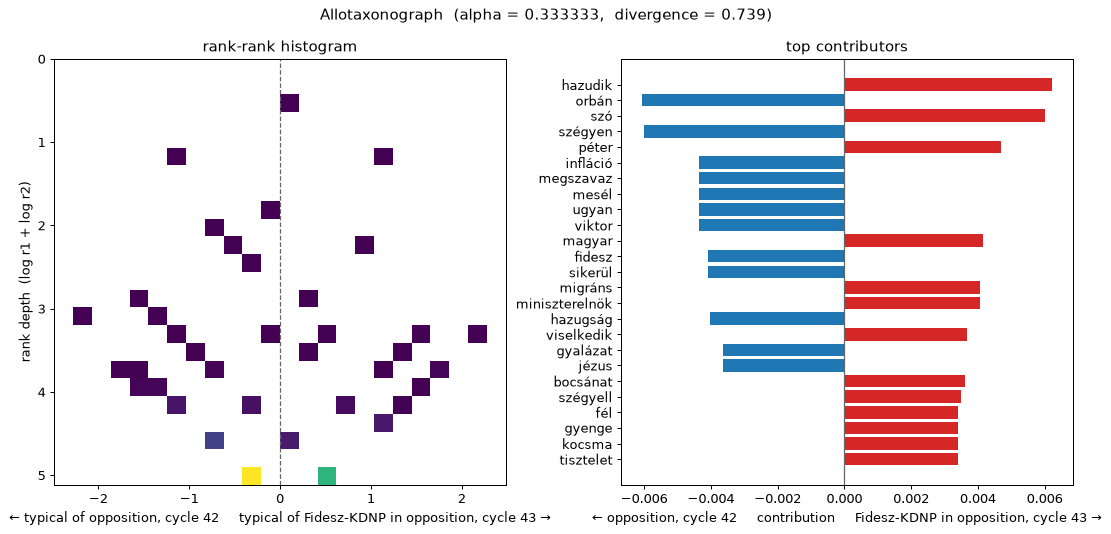

In [17]:
fig = allotaxonograph(ranked["opposition (42)"], ranked["Fidesz-KDNP, in opposition (43)"],
                      alpha=PARAMS["rtd_alpha"], labels=("opposition, cycle 42", "Fidesz-KDNP in opposition, cycle 43"), top=25)
# keyflux returns a bare Figure (no pyplot manager), which the inline backend does not render.
import io
from IPython.display import Image

buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=90, bbox_inches="tight")
Image(buffer.getvalue())

The words that separate the two oppositions are mostly **targets**.

- The cycle-42 opposition heckled *Orbán Viktor*, *Fidesz*, *infláció*
  ("inflation") and *megszavaz* ("you voted for it"). It called things
  *szégyen*, *gyalázat* and *hazugság* ("shame", "disgrace", "a lie").
- Fidesz–KDNP in opposition heckles *Magyar Péter* and the *miniszterelnök*
  ("prime minister"), raises *migráns* ("migrant"), and says *hazudik* ("he's
  lying"). It demands *bocsánat* ("an apology") and tells members to
  *viselkedik* ("behave"). It calls them *gyenge* ("weak") and brings up the
  *kocsma* ("pub").

What remains after the stoplist is close to pure content. A few borderline
words are left: *ugyan* (a particle, "come on"), *szó* (in *szót kér*, "asks
for the floor") and *jézus* (from the exclamation *Jézusom!*). They are kept
because they are words, not function words. Any of them can go through
`PARAMS["stopword_extras"]`.

The target changes with the seat. Whether the register changes too is what the
bootstrap above was testing.

**Caution before reading anything into this.** The cycle-43 groups are mostly
*named* interjections resolved through the registry. The cycle-42 groups are
entirely *unnamed* bench heckles, because named cycle-42 hecklers have no party
data. Unnamed heckles are shorter and more formulaic. So part of every
cycle-42 versus cycle-43 distance measures **route**, not bench or party. A
fair test needs cycle-42 party data for named interjectors, which means a
speeches export for cycle 42 (§8).

## 7. Affect, pooled by bench and cycle

The **Precognox Hungarian Sentiment Lexicon** (CC BY-NC 4.0) supplies
polarity. **Putz Orsolya's emotion dictionaries**, curated for this project and
used with permission, supply the six Ekman emotions. Credit for the emotion
measure is hers. The lists themselves are not redistributable, so only counts
are shown here, never entries.

A heckle averages a handful of words, and a single heckle rarely hits a
dictionary at all. So every bench and cycle is scored as **one pooled text**,
and the hit counts are shown next to each rate.

The lists are not reproduced. Where a few entries dominate a channel's hits,
they are named, as `lexicon.py`'s own documentation does, because a channel
driven by one stock word is measuring that word.

In [18]:
positive = load_lexicon(LEXICONS / "sentiment" / "PrecoPos.txt", "positive")
negative = load_lexicon(LEXICONS / "sentiment" / "PrecoNeg.txt", "negative")
emotions = {name: load_lexicon(LEXICONS / "emotion" / EKMAN_FILES[name], name) for name in EKMAN}
print({lex.name: lex.lexicon_id for lex in (positive, negative, *emotions.values())})


def sentences_of(quote):
    return [([lemma for _, lemma, _ in s], [tag for _, _, tag in s]) for s in cached[quote]]


rows = []
for (c, side), group in quotes.dropna(subset=["side"]).groupby(["cycle", "side"]):
    pooled = [s for quote in group["quote"] for s in sentences_of(quote)]
    sent = score_sentiment(pooled, positive, negative, balanced=PARAMS["sentiment_balanced"])
    emo = score_emotion(pooled, emotions, min_hits=PARAMS["emotion_min_hits"])
    # Reconciliation: pooled hit counts equal the per-quote sums (negation scope never crosses a sentence).
    per_quote = [score_sentiment(sentences_of(q), positive, negative) for q in group["quote"] if cached[q]]
    assert sent.positive == sum(r.positive for r in per_quote) and sent.negative == sum(r.negative for r in per_quote)
    rows.append({"cycle": c, "side": side, "quotes": len(group), "tokens": sent.n_tokens,
                 "pos hits": sent.positive, "neg hits": sent.negative, "polarity": round(sent.polarity, 3),
                 "emotion hits": emo.n_hits, "sparse": emo.sparse,
                 **{f"{name} /1k": round(emo.rates[name] * 1000, 2) for name in EKMAN}})
affect = pd.DataFrame(rows).set_index(["cycle", "side"])
affect

{'positive': 'PrecoPos.txt@1ce3b3d6d3d8', 'negative': 'PrecoNeg.txt@40acc7262918', 'anger': 'emo_duh_full.txt@21489ccc6a65', 'disgust': 'emo_undor_full.txt@30e52b30ec20', 'fear': 'emo_felelem_full.txt@ecfd38ec3238', 'joy': 'emo_orom_full.txt@d8f86ad7ce0c', 'sadness': 'emo_banat_full.txt@37b130ec68d1', 'surprise': 'emo_meglepodes_full.txt@b3b625e2eb59'}


quotes  tokens  pos hits  neg hits  polarity  emotion hits  sparse  anger /1k  disgust /1k  fear /1k  joy /1k  sadness /1k  \
cycle side                                                                                                                                     
39    government    1606    4057       109       181    -0.248           123   False       0.49         6.41      0.74     6.16        15.53   
      opposition    1748    4674       138       239    -0.268           146   False       1.07         5.35      0.43     8.34        13.05   
40    government     554    1382        43        68    -0.225            43   False       1.45         7.24      0.00     6.51        15.92   
      opposition    1587    4571       117       210    -0.284            89   False       0.88         3.94      0.66     4.81         8.97   
41    government     936    2116        49       145    -0.495            74   False       0.94        12.29      0.00     6.62        14.65   
      opposition    1046    3074        78       187    -0.411           125   False       0.98        11.39      1.63     9.43        15.62   
42    government     518    1168        28        51    -0.291            33   False       0.86         8.56      0.86     4.28        13.70   
      opposition     474    1139        42        68    -0.236            30   False       1.76         2.63      0.88     6.15        14.93   
43    government     739    2248        75        87    -0.074            46   False       0.44         6.67      0.44     4.00         8.45   
      opposition     944    2819        98        92     0.032            52   False       0.71         5.68      0.71     5.68         4.97   

                  surprise /1k  
cycle side                      
39    government          0.99  
      opposition          2.99  
40    government          0.00  
      opposition          0.22  
41    government          0.47  
      opposition          1.63  
42    government          0.00  
      opposition          0.00  
43    government          0.44  
      opposition          0.71

In [19]:
# Which entries carry each channel, over every attributed quote.
from parlamonitor.lexicon import count_hits

attributed_quotes = quotes.dropna(subset=["side"])["quote"]
rows = []
for name, lex in emotions.items():
    hits = Counter()
    for quote in attributed_quotes:
        hits.update(count_hits([fold(lemma) for s in cached[quote] for _, lemma, _ in s], lex)[1])
    total = sum(hits.values())
    top = hits.most_common(2)
    rows.append({"emotion": name, "hits": total,
                 "top two entries' share": f"{sum(n for _, n in top) / total:.0%}" if total else "—",
                 "top entries": ", ".join(w for w, _ in top)})
pd.DataFrame(rows).set_index("emotion")

,hits,top two entries' share,top entries
emotion,,,
anger,24,29%,"ordít, fenyegetés"
disgust,184,96%,"szégyell, ronda"
fear,18,33%,"gyáva, aggódik"
joy,175,37%,"éljen, vicces"
sadness,332,80%,"jaj, baj"
surprise,28,68%,"elképesztő, döbbenetes"


Two channels are mostly one or two stock words:

- **Sadness** is largely *baj* ("trouble", as in *Mi a baj?* / *Nem baj!*) and
  *jaj* ("oh dear"). Both are conversational interjections, not grief.
- **Disgust** is largely *szégyell*, the verb inside *szégyelld magad*
  ("shame on you").

So in heckles, the sadness channel measures sighing and the disgust channel
measures shaming. Neither should be reported under its Ekman label without
saying so.

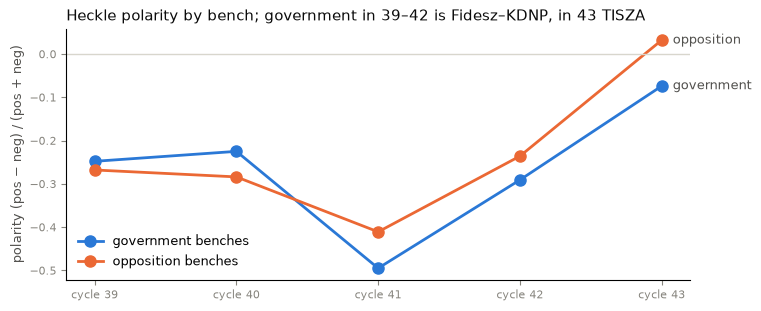

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 3), constrained_layout=True)
colours = {"government": "#2a78d6", "opposition": "#eb6834"}
for side, colour in colours.items():
    sub = affect.xs(side, level="side")
    ax.plot(sub.index, sub["polarity"], marker="o", markersize=8, linewidth=2, color=colour, label=f"{side} benches")
    ax.annotate(f"{side}", (sub.index[-1], sub["polarity"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color="#52514e", fontsize=9)
ax.axhline(0, color="#d8d6cd", linewidth=1)
ax.set_xticks(list(CYCLES), [f"cycle {c}" for c in CYCLES])
ax.set_ylabel("polarity (pos − neg) / (pos + neg)", color="#52514e", fontsize=9)
ax.legend(frameon=False, loc="lower left", fontsize=9)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.tick_params(colors="#86847d", labelsize=8)
ax.set_title("Heckle polarity by bench; government in 39–42 is Fidesz–KDNP, in 43 TISZA",
             loc="left", fontsize=10.5, color="#0b0b0b")
plt.close(fig)
fig

In cycles 39–42, heckling from both benches leans negative, and the two lines
track each other closely. In cycle 43 both move to about zero. On these
numbers, the new parliament's heckling is less negative on both sides, not
just on one.

Three cautions apply:

- **Benches swap in cycle 43.** The orange line is a *bench*, not a party.
- **The Precognox list is 3.4× larger on the negative side**, so every
  unbalanced polarity leans negative by construction. Compare the lines with
  each other and across cycles, not with zero. `balanced=True` is the visible
  alternative.
- **Cycle 43 is mostly named interjections and cycles 39–42 mostly unnamed
  bench heckles** (§1). The cycle-43 shift may partly be that difference in
  route.

## 8. Findings, what to promote, and decisions for you

**Findings**

- **The quotes needed repair before analysis.**
  - `Event.quote` truncation cut about one quote in ten (§1, `reassembled`).
    Here they are reassembled.
  - Hyphenated surnames were dropped entirely by Task 4. Here they are
    recovered and flagged: 1,033 quotes.
  - The block copies from notebook 01 are removed. One 2-line copy alone had
    put a single Vadai Ágnes heckle into cycle 42's top ten.
- **Stock heckles.** Assent leads every cycle, followed by denial and shame.
  The top 20 formulas still cover only 10–15% of heckles, and most heckles are
  said once.
- **Bench attribution is the binding constraint.**
  - Named interjectors in cycles 39–42 have no party in these files, so bench
    keyness for those cycles rests on unnamed heckles and is underpowered.
  - The role-flip comparison (§6), with stopwords removed, shows the cycle
    mostly dominating both bench and party. Against cycle 42, the party's
    heckling stays nearer its own past than the old opposition's (95% of
    bootstrap draws). It mixes route with bench, though.
- **Affect is only measurable pooled, and two channels are mostly stock
  words.** Sadness is *baj*/*jaj* and disgust is *szégyell*. Polarity is
  negative for both benches in 39–42 and near zero for both in 43.

**What to promote**

- **Done:** quote reading, bench attribution and content lemmas now live in
  `src/parlamonitor/heckles.py`. `scripts/heckle_content.py` builds the
  role-flip comparisons from them for the dashboard's allotaxonograph, and
  this notebook imports the same functions.
- **Still open:** fixing `Event.quote` and the hyphenated-name pattern in
  `reactions.py` itself. That changes the `quote` column of
  `reaction_events.csv` and the published heckler counts, so it waits for a
  decision.
- Per-bench pooled affect → `scripts/heckle_content.py`, if it becomes a
  deliverable.

**Decisions for you**

- **Party data for cycles 39–42 named interjectors.** This needs either
  speeches exports for those cycles (the cleanest option, since it also
  unlocks MP-level reaction scores) or an external MP → party table. The
  notebook does not infer it.
- **Emotion channels on heckles.** Report sadness and disgust under what they
  measure here, or drop them for this register.
- **The stoplist for heckles.** The project list (spaCy, light verbs, address
  terms) plus four repaired NLTK words. It cleans the allotaxonograph, but it
  removes *van*, which was the one cross-cycle bench signal (§5). Keeping light
  verbs for heckles is a defensible alternative.
- **Content words only** for keyness and RTD. Heckles lean on function words
  and particles (*hát*, *na*, *ugye*), so keeping them would show style rather
  than topic.
- **Balanced or unbalanced sentiment** for any published figure.